# Embeddings - sözlərin məna əks etditrən ədədi vektor şəklində göstərilməsi

In [38]:
import gensim # Word2Vec, Doc2Vec kimi modul və modellərlə işləmək üçün kitabxana
from gensim.models import Word2Vec
from gensim import downloader as api

import numpy as np

import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

print(gensim.__version__)

4.4.0


# 1. Word Embeddings

In [39]:
vocab = ['it', 'pişik', 'quş', 'balıq', 'fil']

print("One Hot Encoding:")
print('-' * 50)

for i, word in enumerate(vocab):
    one_hot = np.zeros(len(vocab), dtype=int)
    one_hot[i] = 1
    print(f'{word:10}: {one_hot}')

print('-' * 50)
print('Dense embeddings:')
print('-' * 50)
embeddings_index = {
    'it':np.array([0.8, 0.2, -0.1, 0.5]), # Ev heyvanları
    'pişik':np.array([0.7, 0.3, -0.2, 0.5]), # bənzər
    'quş':np.array([0.1, 0.9, 0.8, -0.1]), # uçanlar - fərqli
    'balıq':np.array([-0.5, 0.1, 0.1, 0.9]), # üzənlər tamam fərqli
    'fil':np.array([0.6, 0.4, -0.3, 0.4]) # iri heyvanlar
}

for word, vec in embeddings_index.items():
    print(f'{word:10}: {vec}')

One Hot Encoding:
--------------------------------------------------
it        : [1 0 0 0 0]
pişik     : [0 1 0 0 0]
quş       : [0 0 1 0 0]
balıq     : [0 0 0 1 0]
fil       : [0 0 0 0 1]
--------------------------------------------------
Dense embeddings:
--------------------------------------------------
it        : [ 0.8  0.2 -0.1  0.5]
pişik     : [ 0.7  0.3 -0.2  0.5]
quş       : [ 0.1  0.9  0.8 -0.1]
balıq     : [-0.5  0.1  0.1  0.9]
fil       : [ 0.6  0.4 -0.3  0.4]


kosinusial bənzərlik

$$
\cos{(\theta)} = \frac{A \cdot B}{\|A\| \times \|B\|}
$$

- $A$ $B$ - müqayisə etdiyimiz vektorlar
- $A \cdot B$ - vektorların skalyar hasili (Dot product)
- $\|A\|$- A vektorunun uzunluğu (Magnitude)
- $\|B\|$- B vektorunun uzunluğu (Magnitude)
- $\theta$ - iki vector arasında bucaq

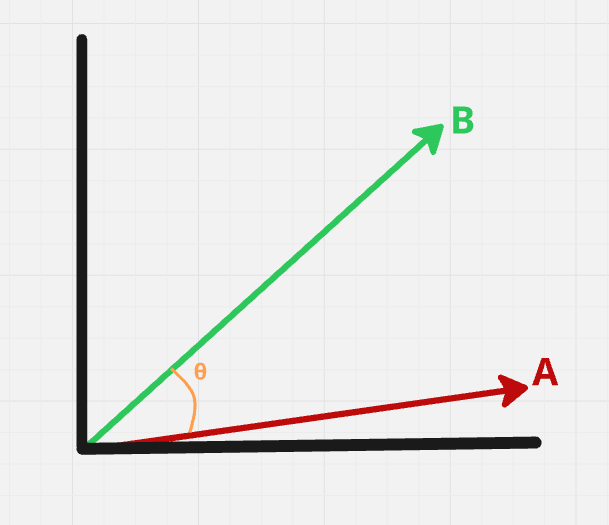
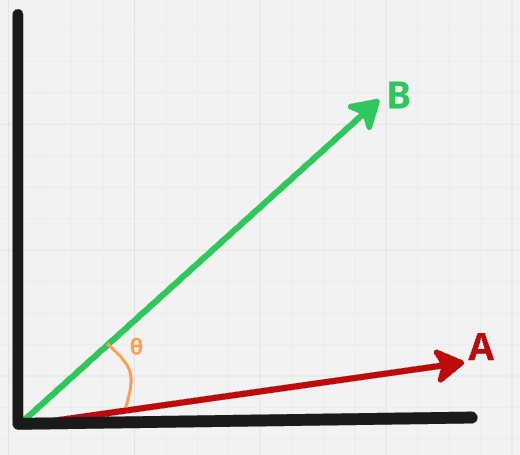
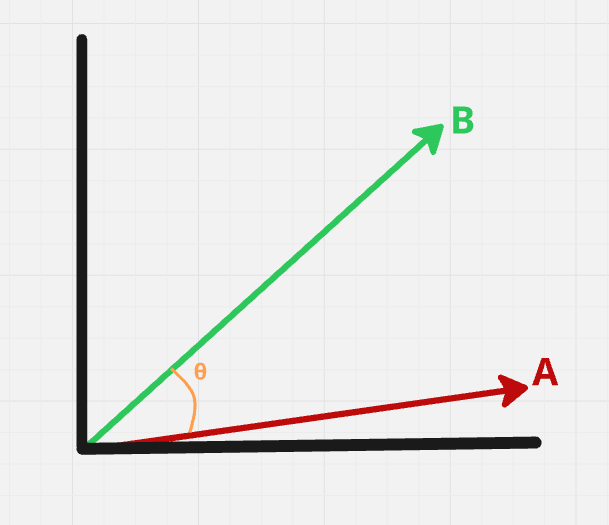

In [40]:
# vektorlar arasında kosinusial bənzərliklərin hesablanması
def cosine_similarity(vec1, vec2):
    dot_product = np.dot(vec1, vec2)

    norm1 = np.linalg.norm(vec1) # = sqrt(a1² + a2² + ...)
    norm2 = np.linalg.norm(vec2) # = sqrt(b1² + b2² + ...)

    return dot_product/(norm1 * norm2)

print('Cosine Similarity:')
print('-' * 50)

words = list(embeddings_index.keys())

for i in range(len(words)):
    for j in range(i+1, len(words)):
        word1, word2 = words[i], words[j]
        sim = cosine_similarity(embeddings_index[word1], embeddings_index[word2])
        print(f'{word1:10} - {word2:10} =  {sim}')

Cosine Similarity:
--------------------------------------------------
it         - pişik      =  0.9841616856627443
it         - quş        =  0.11059124777543396
it         - balıq      =  0.05954913341754135
it         - fil        =  0.9285767423913251
pişik      - quş        =  0.1149542569667464
pişik      - balıq      =  0.11348048444153172
pişik      - fil        =  0.9774284999977502
quş        - balıq      =  0.023809523809523815
quş        - fil        =  0.13159033899195383
balıq      - fil        =  0.07676103107863971


# 2. Word2Vec: Öz modellərimizin öyrədilməsi

In [57]:
import json
with open("word2vec_korpus.json", "r", encoding="utf-8") as file:
    corpus = json.load(file)


print(f'{len(corpus)} sentences found')
print(f'Sentences example {corpus[0]}')

all_words = set()
for sentence in corpus:
    all_words.update(sentence)
print(f'{len(all_words)} unique words found')

1000 sentences found
Sentences example ['proqramlaşdırma', 'dərsində', 'müəllim', 'python', 'java', 'və', 'csharp', 'dillərinin', 'oxşar', 'tərəflərini', 'izah', 'edir', 'və', 'komanda', 'üzvləri', 'layihənin', 'kodunu', 'birlikdə', 'oxuyur', 'və', 'təkmilləşdirirlər']
620 unique words found


In [59]:
model = Word2Vec(
    sentences=corpus,
    vector_size=50,
    window=5,
    min_count=1,
    workers=4,
    epochs=100,
    sg=1 # sg=1 Skip-gram (sözə görə kontekxt), sg=0  CBOW (kontekstə görə söz)
)

print(len(model.wv))
print(model.wv.vector_size)
print(list(model.wv.key_to_index.keys())[:5])

620
50
['və', 'edir', 'zamanda', 'eyni', 'bu']


In [60]:
python_vector = model.wv['python']
java_vector = model.wv['java']

print(python_vector[:10])
print(java_vector[:10])

[-0.8240598  -1.2986002   0.06958901 -0.49570644 -0.46030182  0.40879396
  0.49638298  0.8697382   0.36693227 -0.4761264 ]
[ 0.03391796 -0.34328577 -0.40266034  1.1104203  -0.9087068   1.0394193
  0.3589381   0.02371236 -0.44398895 -0.03282809]


In [61]:
similar_to_python = model.wv.most_similar('python', topn=10)

for word, similarity in similar_to_python:
    print(f'{word:10}: {similarity:.4f}')

print('-' * 50)
similar_to_dog = model.wv.most_similar('it', topn=10)

for word, similarity in similar_to_dog:
    print(f'{word:10}: {similarity:.4f}')

dərsində  : 0.5550
dillərində: 0.5307
java      : 0.5265
avtomatlaşdırma: 0.5156
kitabxanaları: 0.5146
məşqlərlə : 0.5140
emalı     : 0.5031
modellərinin: 0.4849
proqramçıya: 0.4845
nümunələrini: 0.4767
--------------------------------------------------
üsullarla : 0.6186
qururlar  : 0.6114
hekayələr : 0.6085
insanlarla: 0.6007
danışırlar: 0.5936
sadiq     : 0.5854
həyətdə   : 0.5840
onunla    : 0.5837
vaxt      : 0.5814
içir      : 0.5705


In [62]:
similar_python_to_java = model.wv.similarity('python', 'java')
print(f'Similar to Python: {similar_python_to_java}')

similar_python_to_csharp = model.wv.similarity('python', 'csharp')
print(f'Similar to Python: {similar_python_to_csharp}')

similar_python_to_developer = model.wv.similarity('python', 'proqramçı')
print(f'Similar to Python: {similar_python_to_developer}')

Similar to Python: 0.526544451713562
Similar to Python: 0.4009007215499878
Similar to Python: 0.3592627942562103
